# Import important libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from google.colab import drive

# Loading dataset

In [ ]:
drive.mount('/content/drive')
path="/content/drive/MyDrive/Colab Notebooks/HouseRent"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data = pd.read_csv(f"{path}/House_Rent_Dataset.csv")
data

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,5/18/2022,2,15000.0,1000.0,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2.0,Contact Owner
4742,5/15/2022,3,29000.0,2000.0,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Owner
4743,7/10/2022,3,35000.0,1750.0,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Agent
4744,7/6/2022,3,45000.0,1500.0,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2.0,Contact Agent


# Understaning data
- Posted On --> Date the listing was posted
- BHK --> Number of bedrooms, plus hall and kitchen. 2 BHK means 2 bedrooms, 1 hall, 1 kitchen
- Rent --> Monthly rent in Indian rupees (INR). This is usually the target you predict
- Size --> Size of the property in square feet
- Floor --> Which floor the unit is on and the building’s total floors, e.g. Ground out of 2 or 3 out of 5
- Area Type --> How the size was measured: Super Area (includes shared space like corridors and lobby), Carpet Area (usable floor space inside the walls), or Built Area
- Area Locality --> Neighborhood or locality name
- City --> Kolkata, Mumbai, Bangalore, Delhi, Chennai or Hyderabad
- Furnishing Status -->	Furnished, Semi-Furnished or Unfurnished
- Tenant Preferred	--> Who the owner wants to rent to: Bachelors, Family, or Bachelors/Family
- Bathroom	--> Number of bathrooms
- Point of Contact	--> Who you contact about the listing: Owner, Agent or Builder

# EDA

## Data overview

In [ ]:
data.shape

(4746, 12)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [ ]:
data['Posted On'] = pd.to_datetime(data['Posted On'], errors='coerce')

In [ ]:
numerical_features = ['BHK', 'Rent', 'Size', 'Bathroom']
date_features = ['Posted On']
categorical_features = ['Floor', 'Area Type', 'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.isnull().sum()

,0
Posted On,0
BHK,0
Rent,5
Size,8
Floor,0
Area Type,7
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


In [ ]:
data.describe()

,Posted On,BHK,Rent,Size,Bathroom
count,4746,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2022-06-07 18:01:40.126422272,2.083860,3.502340e+04,967.936049,1.965837
min,2022-04-13 00:00:00,1.000000,1.200000e+03,10.000000,1.000000
25%,2022-05-20 00:00:00,2.000000,1.000000e+04,550.000000,1.000000
50%,2022-06-10 00:00:00,2.000000,1.600000e+04,850.000000,2.000000
75%,2022-06-28 00:00:00,3.000000,3.300000e+04,1200.000000,2.000000
max,2022-07-11 00:00:00,6.000000,3.500000e+06,8000.000000,10.000000
std,NaN,0.832256,7.814214e+04,634.562635,0.884904


In [ ]:
data[data.isnull().any(axis=1)]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
1,2022-05-13,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,2022-07-04,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
8,2022-06-07,2,26000.0,NaN,1 out of 2,Carpet Area,"Palm Avenue Kolkata, Ballygunge",Kolkata,Unfurnished,Bachelors,NaN,Contact Agent
10,2022-05-23,3,25000.0,1200.0,1 out of 4,Carpet Area,"Action Area 1, Rajarhat Newtown",Kolkata,Semi-Furnished,Bachelors/Family,NaN,Contact Agent
12,2022-05-14,1,6500.0,250.0,1 out of 4,NaN,"Tarulia, Keshtopur",Kolkata,Furnished,Bachelors,1.0,Contact Owner
14,2022-05-05,3,NaN,900.0,Ground out of 2,Carpet Area,Paschim Barisha,Kolkata,Unfurnished,Bachelors,NaN,Contact Owner
15,2022-06-01,3,40000.0,1286.0,1 out of 1,NaN,New Town Action Area 1,Kolkata,Furnished,Bachelors/Family,2.0,Contact Owner
17,2022-06-20,2,10000.0,800.0,Ground out of 2,NaN,Behala,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
21,2022-06-14,2,9000.0,400.0,2 out of 3,NaN,"Garia Station, Garia",Kolkata,Unfurnished,Bachelors,2.0,Contact Owner
26,2022-06-18,1,NaN,355.0,1 out of 1,Carpet Area,Dum Dum,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Agent


In [ ]:
data = data.dropna()
data.isnull().any().any()

np.False_

In [ ]:
data_filtered = data.copy()
for feature in numerical_features:
  Q1 = data[feature].quantile(0.25)
  Q3 = data[feature].quantile(0.75)
  IQR = Q3 - Q1
  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR
  data_filtered = data_filtered[data_filtered[feature].between(lower, upper)]

In [ ]:
data_filtered.shape

(4111, 12)

## Rent Distribution

In [ ]:
data.nlargest(10, 'Rent')

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
1837,2022-06-08,3,3500000.0,2500.0,4 out of 4,Carpet Area,Marathahalli,Bangalore,Semi-Furnished,Bachelors,3.0,Contact Agent
1001,2022-06-01,4,1200000.0,5000.0,4 out of 15,Carpet Area,Juhu,Mumbai,Semi-Furnished,Bachelors/Family,4.0,Contact Agent
827,2022-05-18,4,1000000.0,3064.0,18 out of 45,Carpet Area,"Raheja Artesia, Worli",Mumbai,Semi-Furnished,Family,4.0,Contact Agent
1329,2022-06-23,4,850000.0,3200.0,2 out of 4,Carpet Area,Breach Candy,Mumbai,Furnished,Bachelors/Family,4.0,Contact Agent
1459,2022-06-27,4,700000.0,3200.0,24 out of 24,Carpet Area,"Lady Ratan Tower, Worli",Mumbai,Furnished,Bachelors/Family,4.0,Contact Agent
1484,2022-07-07,4,680000.0,1962.0,18 out of 20,Carpet Area,Khar West,Mumbai,Semi-Furnished,Bachelors/Family,5.0,Contact Agent
1319,2022-05-31,5,650000.0,3000.0,8 out of 10,Carpet Area,Khar West,Mumbai,Semi-Furnished,Bachelors/Family,5.0,Contact Agent
726,2022-06-20,4,600000.0,2500.0,12 out of 13,Carpet Area,"Mount Marry, Bandra West",Mumbai,Semi-Furnished,Bachelors/Family,4.0,Contact Agent
792,2022-06-13,5,600000.0,3200.0,10 out of 16,Carpet Area,Bandra East,Mumbai,Semi-Furnished,Bachelors/Family,5.0,Contact Agent
1384,2022-05-27,5,600000.0,4500.0,7 out of 20,Carpet Area,Bandra West,Mumbai,Furnished,Bachelors,5.0,Contact Agent


In [ ]:
data = data.drop(index=1837)

**Insight — Clean the data**

removed one listing (index 1837) from the dataset before the analysis. It is a 3 BHK, 2,500 sq ft apartment in Marathahalli, Bangalore, with a monthly rent of 3,500,000. That is about three times the next-highest rent in the data (1,200,000 for a 5,000 sq ft, 4 BHK home in Juhu, Mumbai) and far above every other Bangalore listing, so it is most likely a data-entry error. It also distorted the distributions and the Size-Rent correlation.

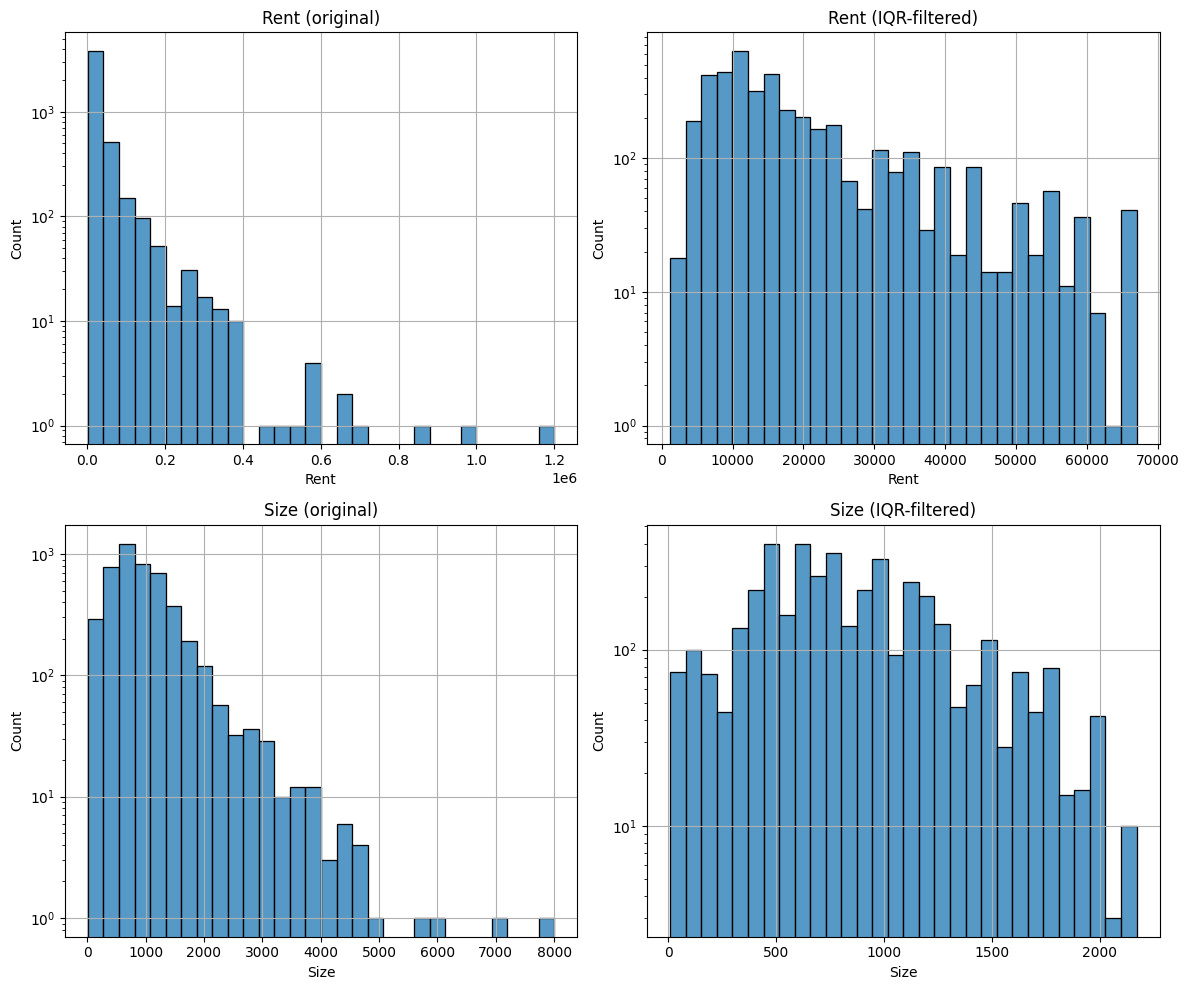

In [ ]:
fig, axes = plt.subplots(2,2, figsize=(12, 10))
for i, feature in enumerate(['Rent', 'Size']):
    ax_orig, ax_filt = axes[i]
    sns.histplot(data=data, x=feature, bins=30, ax=ax_orig)
    sns.histplot(data=data_filtered, x=feature, bins=30, ax=ax_filt)
    ax_orig.set_title(f'{feature} (original)')
    ax_filt.set_title(f'{feature} (IQR-filtered)')
    for ax in (ax_orig, ax_filt):
        ax.grid()
        if feature in ['Rent', 'Size']:
            ax.set_yscale('log')
plt.tight_layout()
plt.show()

**Insight — Rent Distribution**

Before filtering, the rent distribution is extremely right-skewed. Almost all listings (about 4,000) fall in the first bin, and the counts drop quickly in a thin tail that reaches about 1.2 million, where only isolated listings remain. On the linear x-axis, this tail compresses the bulk of the data against the left edge, so the original plot reveals little about typical rents. After filtering, the range shrinks to about 67,000 and the shape becomes visible: rents peak around 10,000-12,000 (over 600 listings), then decline steadily with a long tail of expensive listings. The bin widths differ between the two plots (about 40,000 vs about 2,200), so bar heights should not be compared directly.

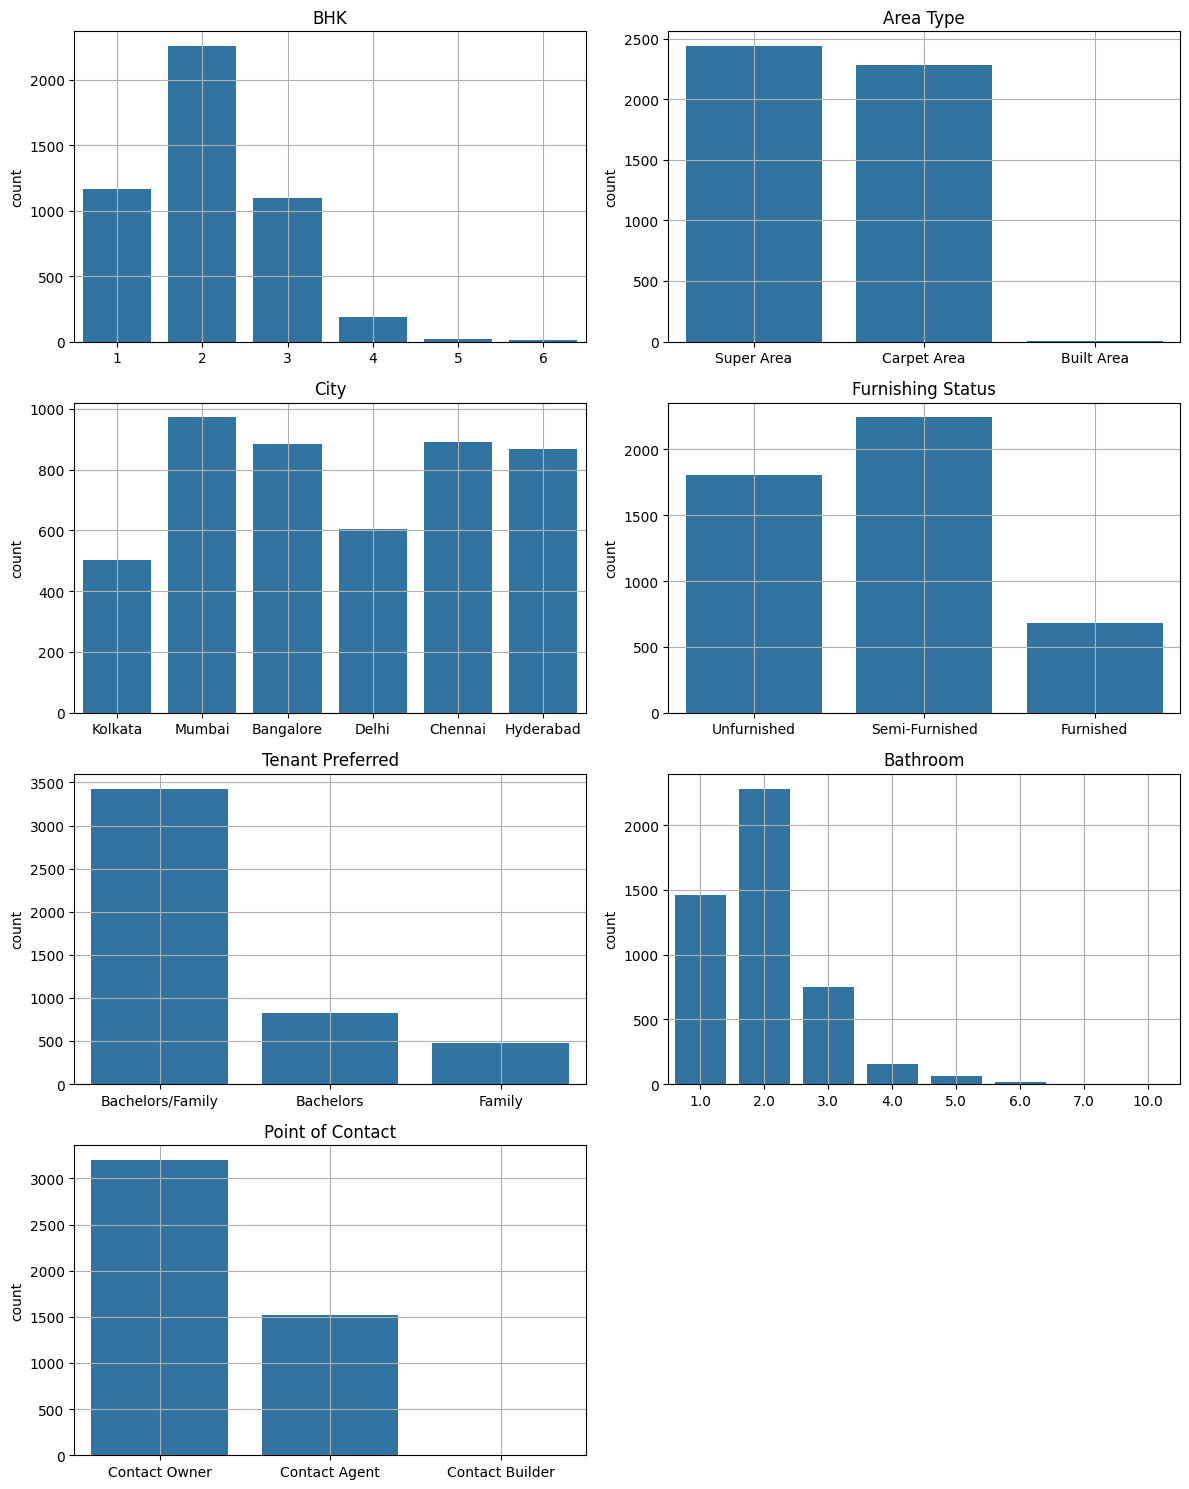

In [ ]:
fig, axes = plt.subplots(4,2, figsize=(12, 15))
for i, feature in enumerate(['BHK', 'Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Bathroom', 'Point of Contact']):
    ax = axes.flat[i]
    sns.countplot(data=data, x=feature, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('')
    ax.grid()
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

**Insight — Rent Distribution**

1. **BHK and Bathroom:** Most listings are small. 2 BHK is the most common (about 2,260), followed by 1 BHK (about 1,170) and 3 BHK (about 1,100), while 4 BHK or larger is rare (about 190 for 4 BHK, and only a handful for 5 and 6). Bathrooms follow the same pattern: 2 bathrooms (about 2,280) is the most common, then 1 (about 1,460) and 3 (about 750), with very few listings above 4.
2. **Area Type:** Listings are split almost evenly between Super Area (about 2,440) and Carpet Area (about 2,290). Built Area is almost absent, so it carries very little information.
3. **City:** Listings are fairly balanced across the six cities. Mumbai has the most (about 970), followed by Chennai, Bangalore and Hyderabad (about 870-890 each), then Delhi (about 600) and Kolkata (about 500).
4. **Furnishing Status:** Semi-furnished is the most common (about 2,250), followed by unfurnished (about 1,800). Fully furnished listings are the minority (about 680).
5. **Tenant Preferred:** Most listings accept both bachelors and families (about 3,440). Listings that accept only bachelors (about 830) or only families (about 480) are much less common.
6. **Point of Contact:** Most listings are handled by the owner (about 3,210), about 1,530 by an agent, and almost none by a builder.


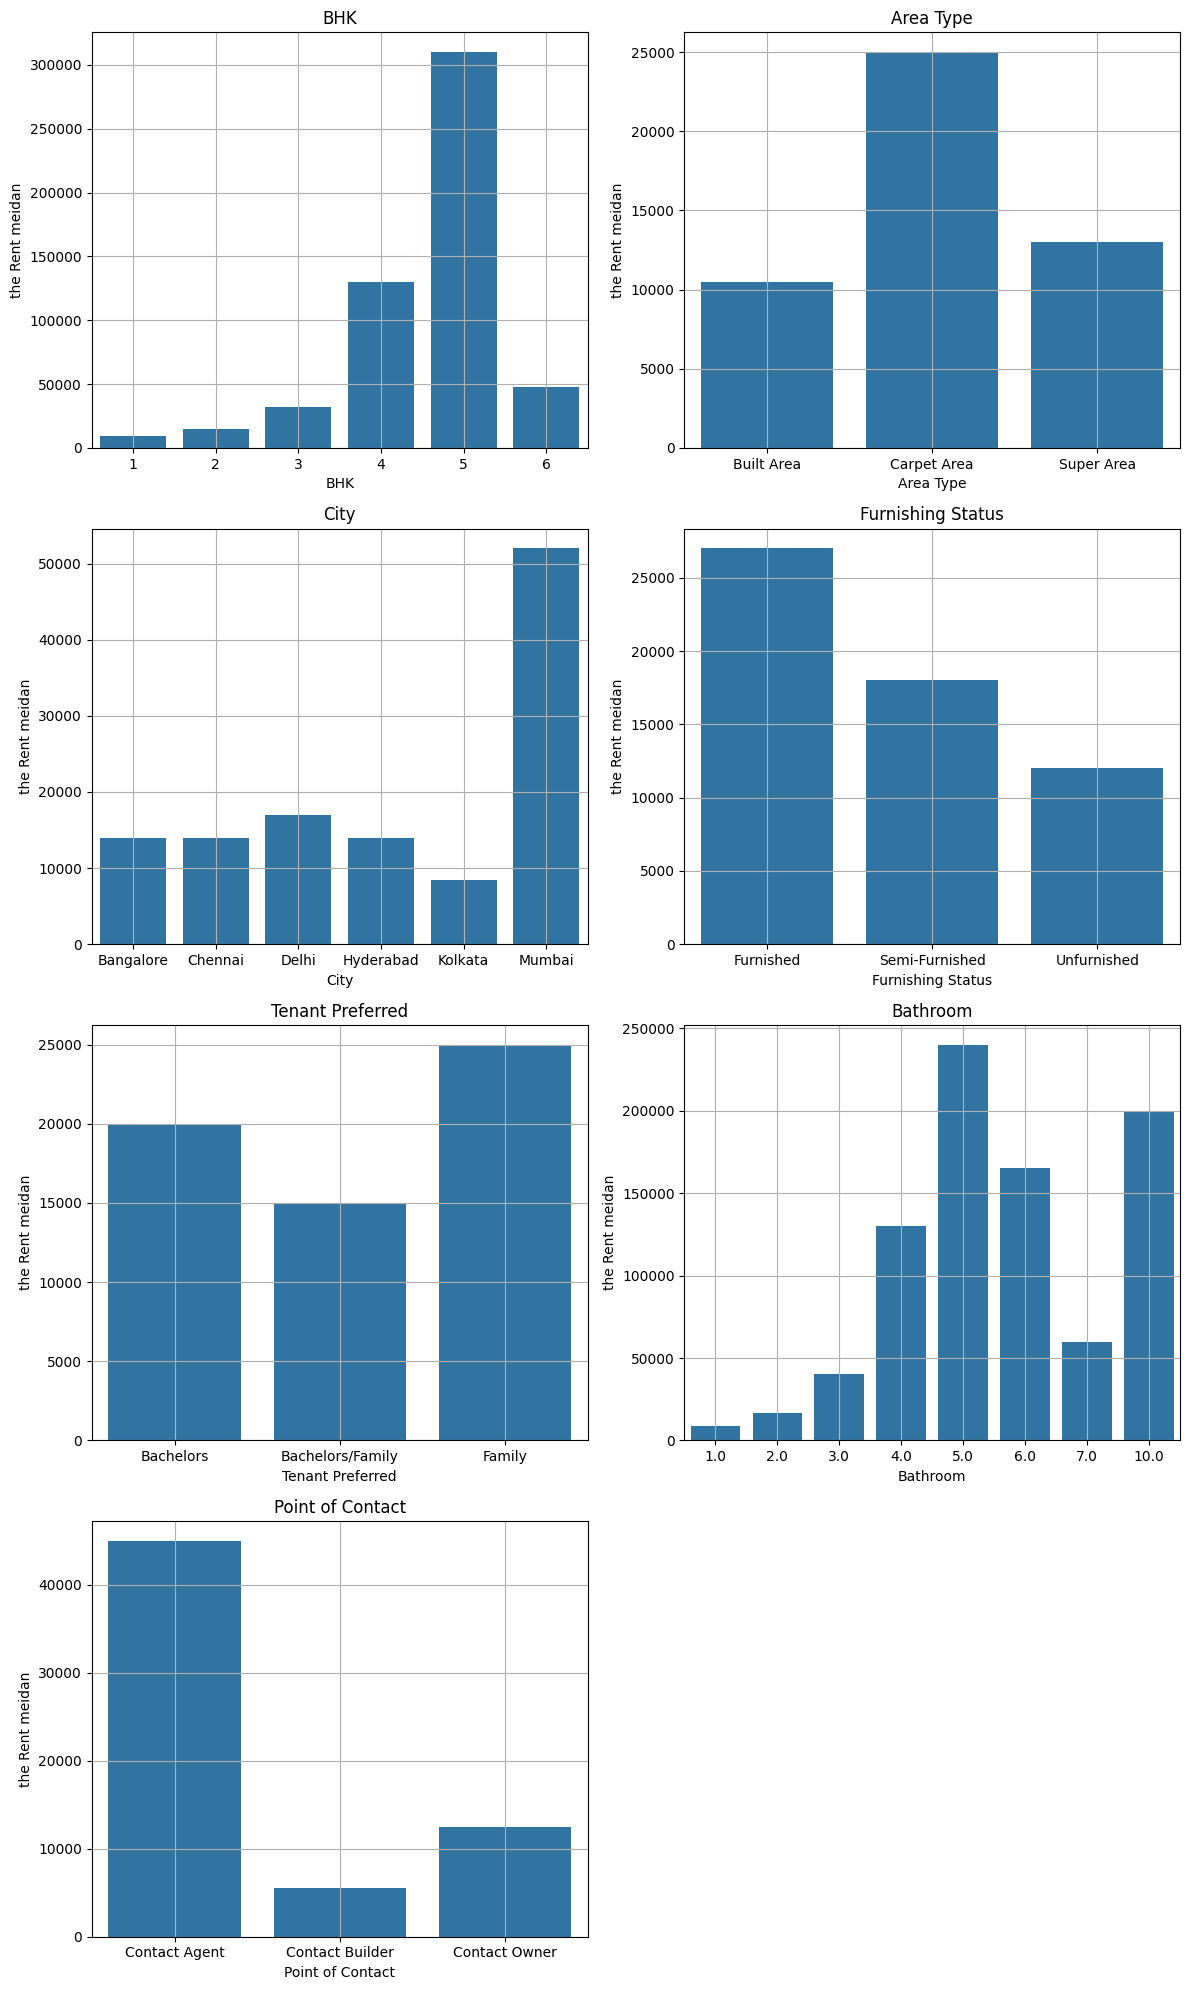

In [ ]:
fig, axes = plt.subplots(4,2, figsize=(12, 20))
for i, feature in enumerate(['BHK', 'Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Bathroom', 'Point of Contact']):
    ax = axes.flat[i]
    medians = data.groupby(feature)['Rent'].median()
    sns.barplot(x=medians.index, y=medians.values, ax=ax)
    ax.set_title(feature)
    ax.set_ylabel('the Rent meidan')
    ax.grid()
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

## Size

### Size vs. Rent

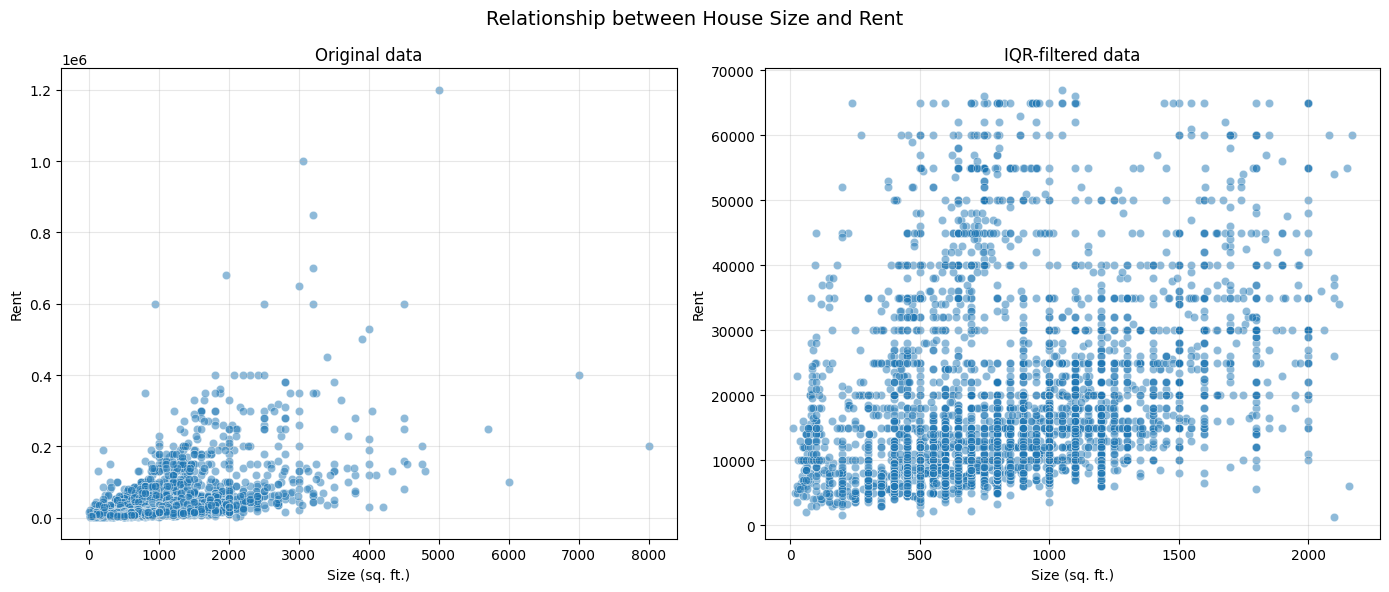

In [ ]:
fig, (ax_org, ax_filt) = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=data, x='Size', y='Rent', ax=ax_org, alpha=0.5)
sns.scatterplot(data=data_filtered, x='Size', y='Rent', ax=ax_filt, alpha=0.5)
ax_org.set_title('Original data')
ax_filt.set_title('IQR-filtered data')
for ax in (ax_org, ax_filt):
    ax.set_xlabel('Size (sq. ft.)')
    ax.set_ylabel('Rent')
    ax.grid(alpha=0.3)
fig.suptitle('Relationship between House Size and Rent', fontsize=14)
plt.tight_layout()
plt.show()

### Size Vs. Rent Across Cities

/tmp/ipykernel_1123/2596602265.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  city_corr = data.groupby('City').apply(


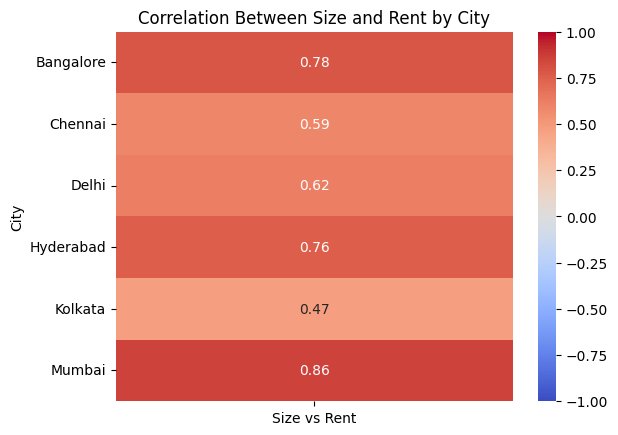

In [ ]:
city_corr = data.groupby('City').apply(
    lambda group: group['Size'].corr(group['Rent'])
).to_frame(name='Size vs Rent')
sns.heatmap(
    city_corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)
plt.title('Correlation Between Size and Rent by City')
plt.show()

**Insight — Relationship Between Size and Rent Across Cities**

Apartment size is positively correlated with rent in every city, but the strength of the relationship varies widely. Mumbai shows the strongest correlation (0.86), followed by Hyderabad (0.76), Delhi (0.62), and Chennai (0.59). Kolkata is moderate (0.47). Bangalore is X, [which is much higher than before the suspicious listing was removed / which is the lowest]. This suggests that the link between size and rent is stronger in some cities than in others, and that a substantial share of the variation is not explained by size. Correlation alone does not establish that size causes higher rent.

## City

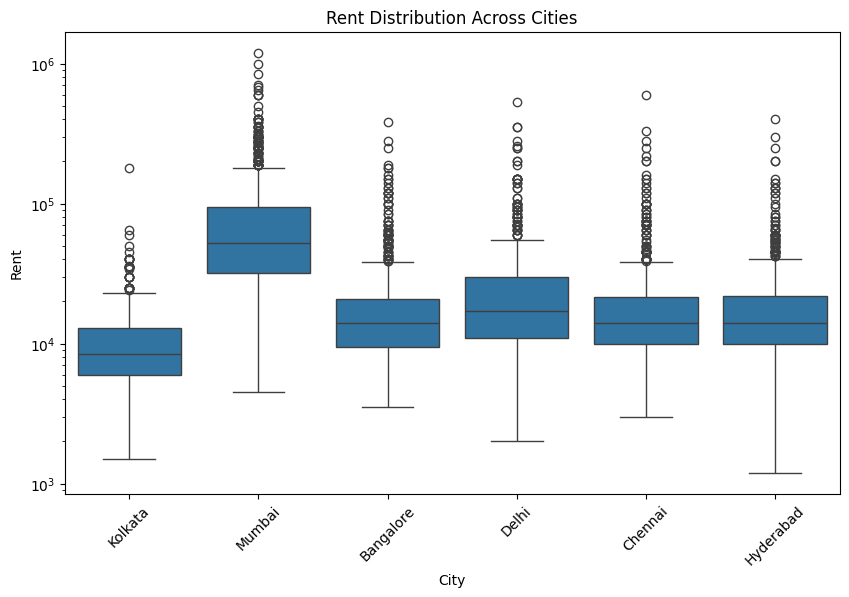

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='City', y='Rent')
plt.title('Rent Distribution Across Cities')
plt.yscale('log')
plt.xticks(rotation=45)
plt.show()

In [ ]:
data.groupby('City')['Rent'].agg(
    ['mean', 'median', 'std']
).sort_values('median', ascending=False)

,mean,median,std
City,,,
Mumbai,85321.204733,52000.0,102525.116720
Delhi,29461.983471,17000.0,43542.047016
Chennai,21614.092031,14000.0,33069.910236
Bangalore,21039.774011,14000.0,27456.847512
Hyderabad,20555.048387,14000.0,26436.196407
Kolkata,11526.331349,8500.0,11152.108850


### Insights — Rent Distribution Across Cities

1. **Mumbai is by far the most expensive city.** Its mean rent (about 85,300) and median rent (52,000) are the highest, and the median is roughly three times that of Delhi (17,000) and more than six times that of Kolkata (8,500).
2. **Kolkata is the cheapest.** Its mean (about 11,500) and median (8,500) are the lowest. Chennai, Bangalore, and Hyderabad are very similar to each other (means of about 20,600-21,600, medians of 14,000), and Delhi sits slightly above them (mean about 29,500, median 17,000).
3. **Mumbai has the most variability.** Its standard deviation (about 102,500) is the largest, and its box in the boxplot is the widest, so rents in Mumbai are spread over a much wider range than elsewhere. Kolkata's spread is the smallest (about 11,200).
4. **Every city is right-skewed.** The mean is higher than the median in all six cities, which shows that a smaller number of high-rent listings pull the averages upward. The boxplot also shows several points above the whiskers in each city, which may be premium properties. Their causes would need further investigation

## Furnishing Status

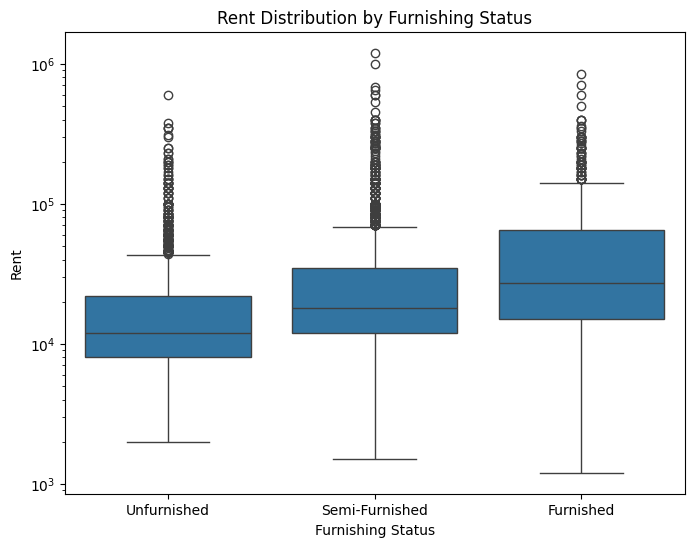

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=data,
    x='Furnishing Status',
    y='Rent'
)
plt.title('Rent Distribution by Furnishing Status')
plt.yscale('log')
plt.show()

In [ ]:
data.groupby('Furnishing Status')['Rent'].agg(
    ['mean', 'median', 'std']
).sort_values('median', ascending=False)

,mean,median,std
Furnishing Status,,,
Furnished,56207.238938,27000.0,80724.908551
Semi-Furnished,37245.449398,18000.0,65710.101377
Unfurnished,22525.537140,12000.0,35259.674335


### Insights — Rent Distribution by Furnishing Status

1. **Rent rises with the level of furnishing.** Furnished apartments have the highest median rent (27,000), followed by semi-furnished (18,000) and unfurnished (12,000). The furnished median is more than twice the unfurnished one.
2. **Furnished apartments have the widest interquartile range.** Their middle 50% of rents spans roughly 15,000 to 65,000, compared with about 12,000 to 35,000 for semi-furnished and 8,000 to 22,000 for unfurnished, so prices vary the most within this group. The standard deviations show the same order (about 80,700, 65,700 and 35,300).
3. **All three groups are right-skewed.** The mean is well above the median in every group (for example, 56,207 vs 27,000 for furnished), and each group has many points above its whiskers, which may be premium properties. Their causes would need further investigation.
4. **The distributions overlap substantially.** The unfurnished and semi-furnished boxes overlap heavily, so furnishing status alone does not clearly separate the rents of individual apartments.

## BHK

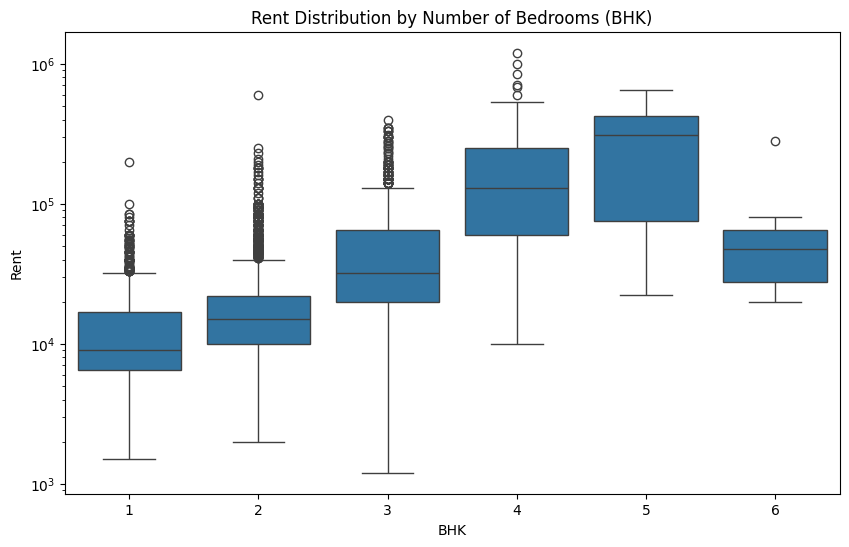

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=data,
    x='BHK',
    y='Rent'
)
plt.yscale('log')
plt.title('Rent Distribution by Number of Bedrooms (BHK)')
plt.show()

In [ ]:
data.groupby('BHK')['Rent'].agg(
    ['mean', 'median', 'std']
).sort_values('median', ascending=False)

,mean,median,std
BHK,,,
5,297500.000000,310000.0,207944.637397
4,168864.555556,130000.0,165788.401565
6,73125.000000,47500.0,86310.796378
3,52842.621795,32000.0,54854.451014
2,22154.635033,15000.0,25849.271048
1,14174.160069,9000.0,13533.433065


### Insights — Rent by BHK

1. **Median rent rises with the number of bedrooms from 1 to 5 BHK.** It goes from 9,000 (1 BHK) to 15,000 (2 BHK), 32,000 (3 BHK), 130,000 (4 BHK) and 310,000 (5 BHK). The median then falls to 47,500 for 6 BHK, but 5 and 6 BHK contain only a handful of listings, so those two values should not be read as a trend.
2. **Variability grows with size.** The boxes for 3 and 4 BHK are much taller than for 1 and 2 BHK, and the standard deviation rises from about 13,500 (1 BHK) to about 165,800 (4 BHK). Because the y-axis is logarithmic, the larger boxes mean a wider spread in percentage terms as well.
3. **Every group is right-skewed.** The mean is above the median in all categories (for example, 22,155 vs 15,000 for 2 BHK), and 1 to 4 BHK show many points above their whiskers, which may be premium properties.
4. **The distributions overlap.** The upper part of the 2 BHK range reaches the rents of typical 3 BHK listings, and the 3 BHK range reaches into the 4 BHK range, so the number of bedrooms alone does not determine rent.

## Bathroom

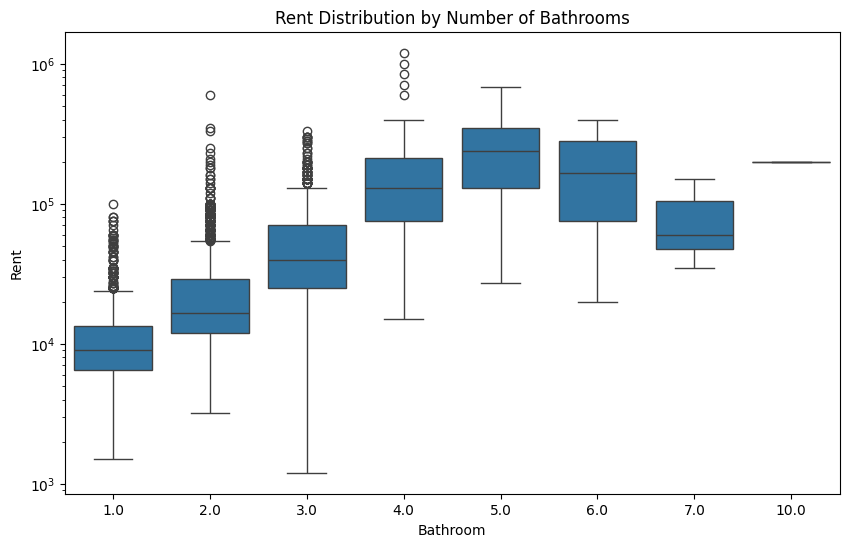

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=data,
    x='Bathroom',
    y='Rent'
)
plt.title('Rent Distribution by Number of Bathrooms')
plt.yscale('log')
plt.show()

In [ ]:
data.groupby('Bathroom')['Rent'].agg(
    ['mean', 'median', 'std']
).sort_values('median', ascending=False)

,mean,median,std
Bathroom,,,
5.0,252350.000000,240000.0,158942.887621
10.0,200000.000000,200000.0,NaN
6.0,177500.000000,165000.0,118100.496497
4.0,167846.153846,130000.0,163527.571074
7.0,81666.666667,60000.0,60484.157705
3.0,58620.277108,40000.0,52336.559705
2.0,25063.648554,16500.0,27026.679749
1.0,11886.288934,9000.0,9637.815580


### Insights — Rent by Number of Bathrooms

1. **Median rent rises with the number of bathrooms up to 5.** It goes from about 9,000 (1 bathroom) to 16,500 (2), 40,000 (3), 130,000 (4) and 240,000 (5). It then falls to 165,000 for 6 bathrooms and 60,000 for 7. The 10-bathroom group is a single listing (200,000), which is why its standard deviation is `NaN` and its box shows as a flat line. Groups with 6 or more bathrooms contain very few listings, so the decline should not be read as a real trend.
2. **Variability grows with the number of bathrooms.** The boxes for 3 to 5 bathrooms are much taller than for 1 and 2, and the standard deviation rises from about 27,000 (2 bathrooms) to about 163,500 (4 bathrooms) and 158,900 (5 bathrooms). Because the y-axis is logarithmic, the larger boxes mean a wider spread in percentage terms as well.
3. **Every group with enough listings is right-skewed.** The mean is above the median in each category (for example, 25,064 vs 16,500 for 2 bathrooms), and the groups with 1 to 4 bathrooms show many points above their whiskers, which may be premium properties.
4. **The distributions overlap.** The upper part of each group's range reaches into the next group's range, so the number of bathrooms alone does not determine rent.


## Correlation Heatmap for numerical features

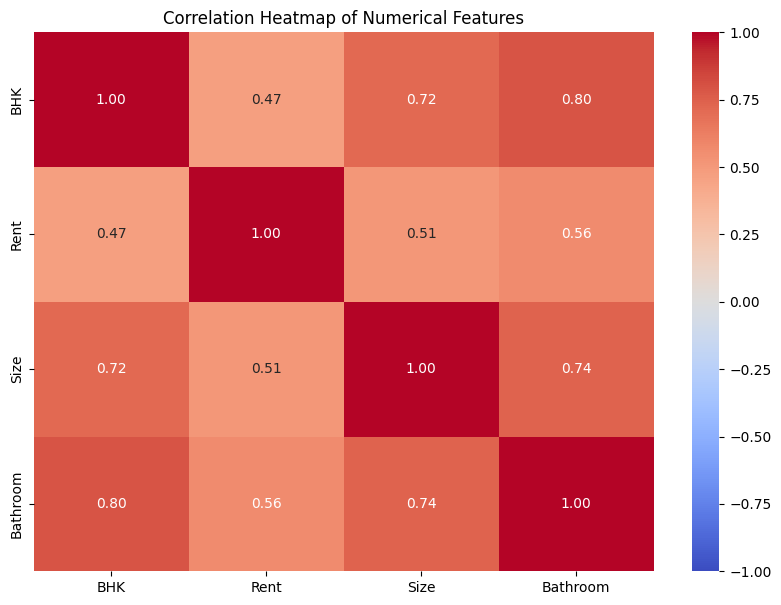

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    data[numerical_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

###Insights — Correlation Heatmap
1. **Rent correlations.** Bathroom has the strongest positive correlation with Rent (0.56), followed by Size (0.51) and BHK (0.47). All three are moderate, so each feature explains only part of the variation in rent (for example, Bathroom's r² is about 0.31).
2. **Relationships between features.** BHK and Bathroom are strongly correlated (0.80), and Size is also strongly correlated with Bathroom (0.74) and BHK (0.72). Larger apartments tend to have more bedrooms and more bathrooms.
3. **Conclusion.** Larger apartments tend to have more bedrooms and bathrooms and higher rents. Because the three features are strongly related to each other, they carry overlapping information about rent, and this overlap (multicollinearity) should be considered when building a model.

# Cleaning

In [ ]:
cleaned_floor = data['Floor'].str.split(' out of ', expand=True)
print(cleaned_floor[cleaned_floor.isnull().any(axis=1)])

           0     1
2553       3  None
2883  Ground  None
4490       1  None
4560       1  None


In [ ]:
cleaned_floor.isnull().sum()

,0
0,0
1,4


In [ ]:
for value in ['Ground', 'Lower Basement', 'Upper Basement']:
  print(len(cleaned_floor[cleaned_floor[0] == value]))
cleaned_floor[0] = cleaned_floor[0].replace({'Ground': '0', 'Upper Basement': '-1', 'Lower Basement': '-2'})
cleaned_floor[0] = pd.to_numeric(cleaned_floor[0], errors='coerce')
cleaned_floor[1] = pd.to_numeric(cleaned_floor[1], errors='coerce')
for value in [0, -1, -2]:
  print(len(cleaned_floor[cleaned_floor[0] == value]))

918
11
23
918
23
11


In [ ]:
cleaned_floor[2] = cleaned_floor[0]/cleaned_floor[1]
cleaned_floor[2]

,2
0,0.000000
2,0.333333
4,0.500000
5,0.000000
6,0.000000
...,...
4741,0.600000
4742,0.250000
4743,0.600000
4744,0.676471


In [ ]:
data_copy = data.drop(columns = ['Floor'])
data_copy['Floor'] = cleaned_floor[2]
data_copy

,Posted On,BHK,Rent,Size,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Floor
0,2022-05-18,2,10000.0,1100.0,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,0.000000
2,2022-05-16,2,17000.0,1000.0,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,0.333333
4,2022-05-09,2,7500.0,850.0,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner,0.500000
5,2022-04-29,2,7000.0,600.0,Super Area,Thakurpukur,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,0.000000
6,2022-06-21,2,10000.0,700.0,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,2.0,Contact Agent,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000.0,1000.0,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2.0,Contact Owner,0.600000
4742,2022-05-15,3,29000.0,2000.0,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Owner,0.250000
4743,2022-07-10,3,35000.0,1750.0,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Agent,0.600000
4744,2022-07-06,3,45000.0,1500.0,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2.0,Contact Agent,0.676471


In [ ]:
data_copy.isnull().sum()

,0
Posted On,0
BHK,0
Rent,0
Size,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0
Bathroom,0


In [ ]:
data_copy = data_copy.dropna()
data_copy.isnull().sum()

,0
Posted On,0
BHK,0
Rent,0
Size,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0
Bathroom,0


In [ ]:
data_copy = data_copy.drop(columns=['Area Locality'])

In [ ]:
days_since_start = (data_copy['Posted On'] - data_copy['Posted On'].min()).dt.days
data_copy['days_since_start'] = days_since_start
data_copy = data_copy.drop(columns=['Posted On'])
data_copy['days_since_start']

,days_since_start
0,35
2,33
4,26
5,16
6,69
...,...
4741,35
4742,32
4743,88
4744,84


In [ ]:
data_copy.isnull().sum()

,0
BHK,0
Rent,0
Size,0
Area Type,0
City,0
Furnishing Status,0
Tenant Preferred,0
Bathroom,0
Point of Contact,0
Floor,0


# Preprocessing

In [ ]:
encoded_features = ['Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']
scale_features = ['Size']
preprocessor = ColumnTransformer(
    transformers=[
        ('scale', StandardScaler(), scale_features),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False), encoded_features)
    ],
    remainder='passthrough'
)

In [ ]:
y = data_copy['Rent']
X = data_copy.drop(columns=['Rent'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
features = preprocessor.get_feature_names_out()
X_train_processed = pd.DataFrame(
    data = X_train_processed,
    columns = features,
    index=X_train.index,
)
X_test_processed = pd.DataFrame(
    data = X_test_processed,
    columns = features,
    index=X_test.index,
)

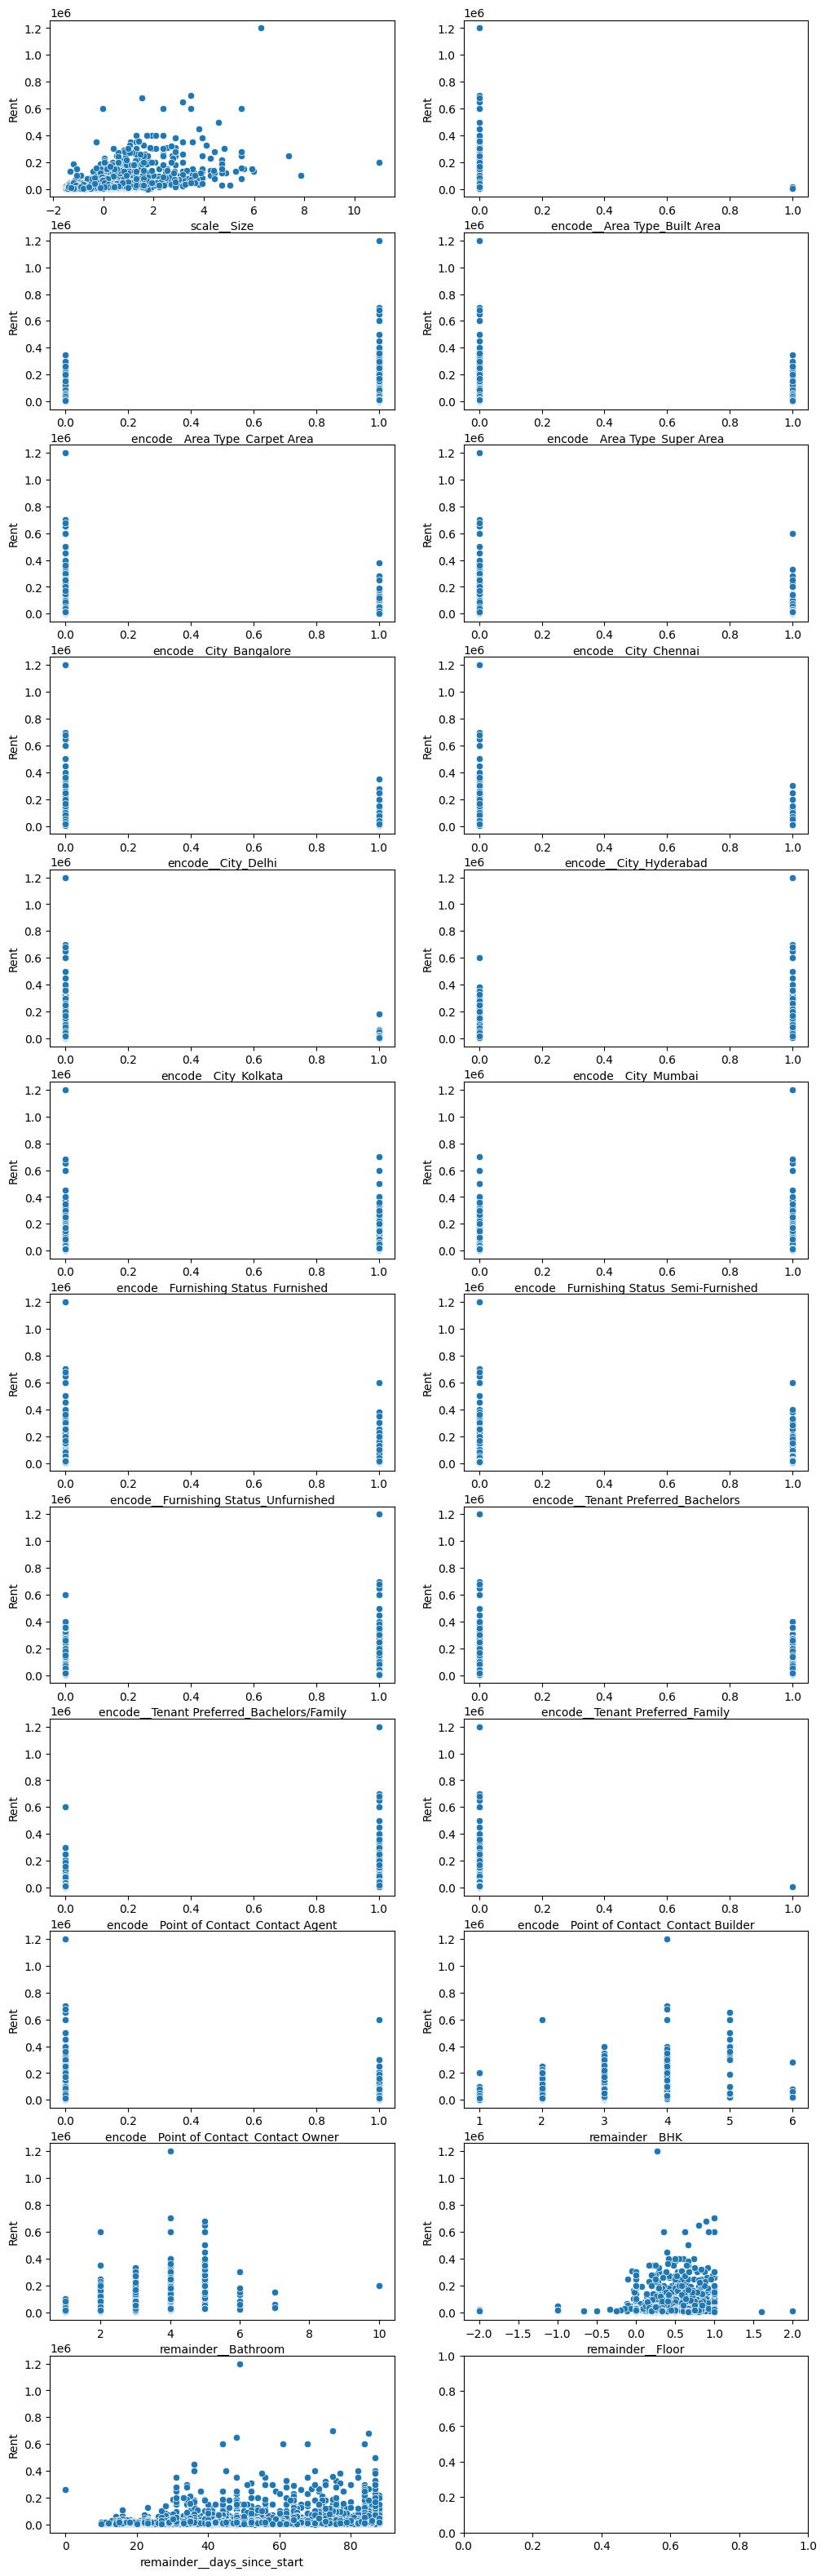

In [ ]:
fig, axes = plt.subplots(12, 2, figsize=(12, 40))
for i, feature in enumerate(X_train_processed.columns):
  ax = axes.flat[i]
  sns.scatterplot(x=X_train_processed[feature], y=y_train, ax=ax)
plt.show()

remainder__Bathroom                          0.572704
scale__Size                                  0.509427
remainder__BHK                               0.483636
encode__City_Mumbai                          0.449505
encode__Point of Contact_Contact Agent       0.439938
encode__Point of Contact_Contact Owner      -0.439564
encode__Area Type_Carpet Area                0.272979
encode__Area Type_Super Area                -0.272536
encode__Furnishing Status_Unfurnished       -0.153243
encode__Furnishing Status_Furnished          0.150087
remainder__days_since_start                  0.148405
encode__City_Kolkata                        -0.134970
encode__City_Hyderabad                      -0.111831
encode__City_Bangalore                      -0.108273
encode__City_Chennai                        -0.105028
encode__Tenant Preferred_Family              0.090604
remainder__Floor                             0.080807
encode__Tenant Preferred_Bachelors/Family   -0.078039
encode__Furnishing Status_Se

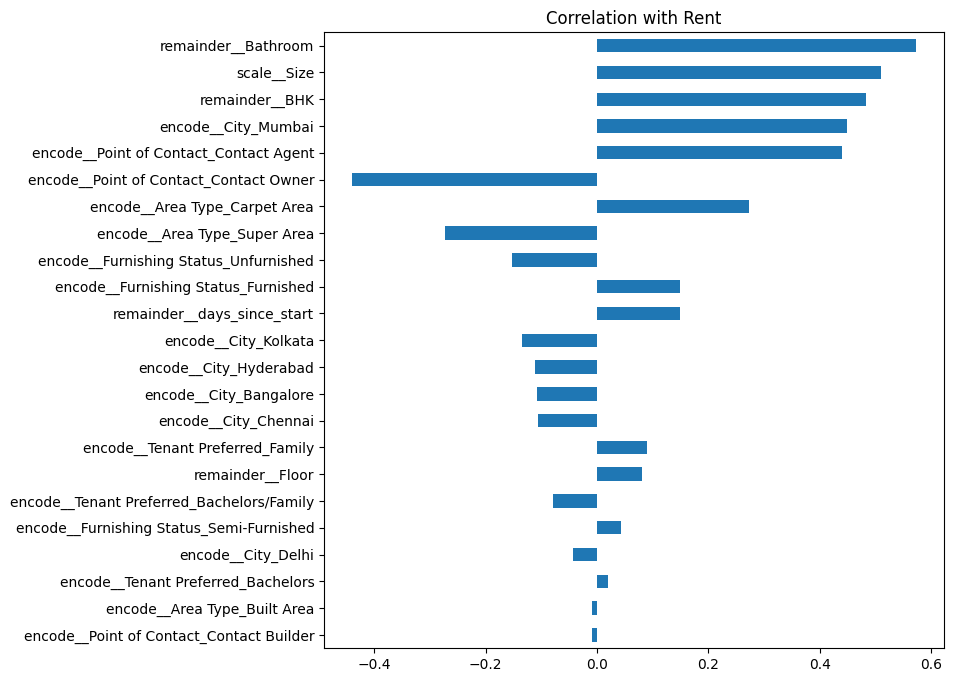

In [ ]:
corr = X_train_processed.corrwith(y_train).sort_values(key=abs, ascending=False)
print(corr)

corr.plot(kind='barh', figsize=(8, 8))
plt.gca().invert_yaxis()
plt.title('Correlation with Rent')
plt.show()

In [ ]:
y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()
y_test_s = y_scaler.transform(y_test.to_numpy().reshape(-1, 1)).ravel()

# Pipeline and Fine Tuning

In [ ]:
models = {
    'LinReg': LinearRegression(),
    'KNNReg' : KNeighborsRegressor(),
    'SVR' : SVR()
}

In [ ]:
param_grids = {
    'LinReg': {
        'model__fit_intercept': [True, False],
        'model__positive': [True, False],
    },
    'KNNReg': {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2],
    },
    'SVR' : {
        "model__C": [1, 10, 100],
        "model__epsilon": [0.01, 0.1],
        "model__gamma": ["scale", 0.01],
    }
}

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
results = {}
for name, model in models.items():
  pipeline = Pipeline([
      ('preprocessor', preprocessor),
      ('model', model)
  ])

  grid = GridSearchCV(
    pipeline,
    param_grids[name],
    scoring = 'neg_mean_squared_error',
    cv = cv,
    n_jobs=-1
  )

  grid.fit(X_train, y_train_s)

  results[name] = {
    "estimator": grid.best_estimator_,
    "cv_score": grid.best_score_,
    "params": grid.best_params_,
  }

  print(f"{name}: {grid.best_score_:.4f}  {grid.best_params_}")

LinReg: -0.4783  {'model__fit_intercept': True, 'model__positive': True}
KNNReg: -0.4484  {'model__n_neighbors': 11, 'model__p': 1, 'model__weights': 'distance'}
SVR: -0.3286  {'model__C': 100, 'model__epsilon': 0.01, 'model__gamma': 0.01}


In [ ]:
summary = pd.DataFrame(
    {k: {"cv_rmse": np.sqrt(-v["cv_score"])} for k, v in results.items()}
).T.sort_values("cv_rmse", ascending=True)
print(summary)

best_name = summary.index[0]
best_model = results[best_name]["estimator"]
print(best_name)

y_pred = best_model.predict(X_test)
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_s, y_pred)):.4f}")
print(f"MAE : {mean_absolute_error(y_test_s, y_pred):.4f}")
print(f"R²  : {r2_score(y_test_s, y_pred):.4f}")

         cv_rmse
SVR     0.573222
KNNReg  0.669632
LinReg  0.691610
SVR
RMSE: 0.6393
MAE : 0.1985
R²  : 0.6443
